# Crop Recommendation — Exploratory Data Analysis

## Objective
Explore soil and environmental conditions to understand how they relate to crop recommendations.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [3]:
# Find the project directory
BASE_DIR = Path.cwd()
print(BASE_DIR)

/home/faraz-ul-hassan/Development/projects/machine-learning/01_Crop_recommendation/notebooks


In [4]:
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

print(BASE_DIR)

/home/faraz-ul-hassan/Development/projects/machine-learning/01_Crop_recommendation


In [5]:
# Load dataset
DATA_PATH = BASE_DIR / "data" / "Crop_recommendation.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
print("DATASET shape: ", df.shape)

DATASET shape:  (2200, 8)


In [7]:
print("First 5 rows: ")
display(df.head())

First 5 rows: 


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


N - ratio of Nitrogen content in soil\
P - ratio of Phosphorous content in soil\
K - ratio of Potassium content in soil\
temperature - temperature in degree Celsius\
humidity - relative humidity in %\
ph - ph value of the soil\
rainfall - rainfall in mm  

In [8]:
print("Column names: ")
print(df.columns.tolist())

Column names: 
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


In [9]:
print("Dataset Information: ")
df.info()

Dataset Information: 
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB


In [10]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [11]:
df['label'].value_counts()

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

In [12]:
df['label'].nunique()

22

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
print("Unique labels:", df['label'].nunique())
print("Duplicate rows:", df.duplicated().sum())

Unique labels: 22
Duplicate rows: 0


In [15]:
df.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

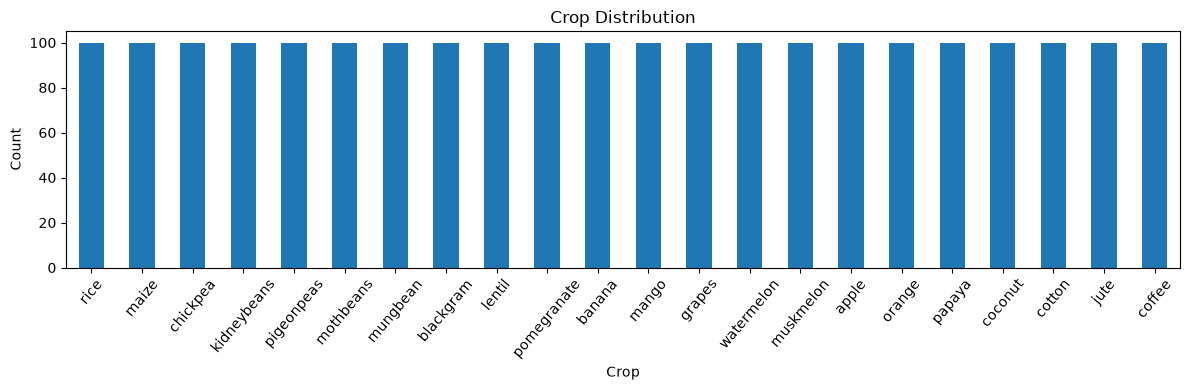

In [54]:
df['label'].value_counts().plot(kind='bar', figsize=(12, 4))
plt.title('Crop Distribution')
plt.xlabel('Crop')
plt.ylabel('Count')
plt.xticks(rotation=50)
plt.tight_layout()
plt.savefig('../figures/crop_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

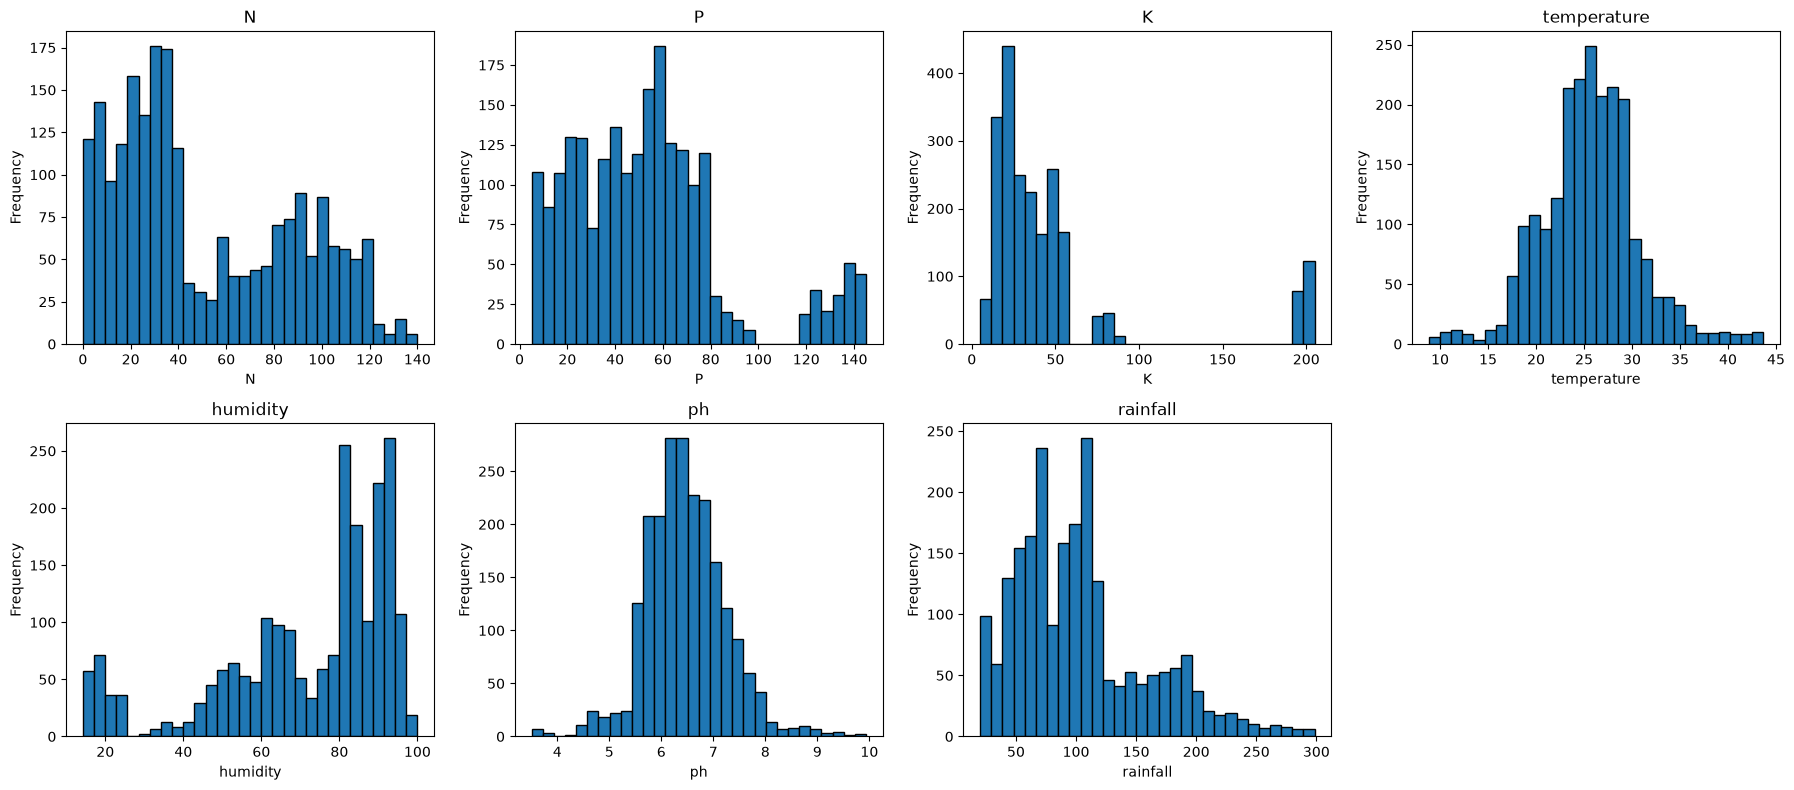

In [53]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

for i, col in enumerate(features):
    axes[i].hist(df[col], bins=30, edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

# hide the unused 8th subplot (we have 7 features, grid is 2x4 = 8 slots)
axes[7].set_visible(False)

plt.tight_layout()
plt.savefig('../figures/histograms.png', dpi=150, bbox_inches='tight')
plt.show()

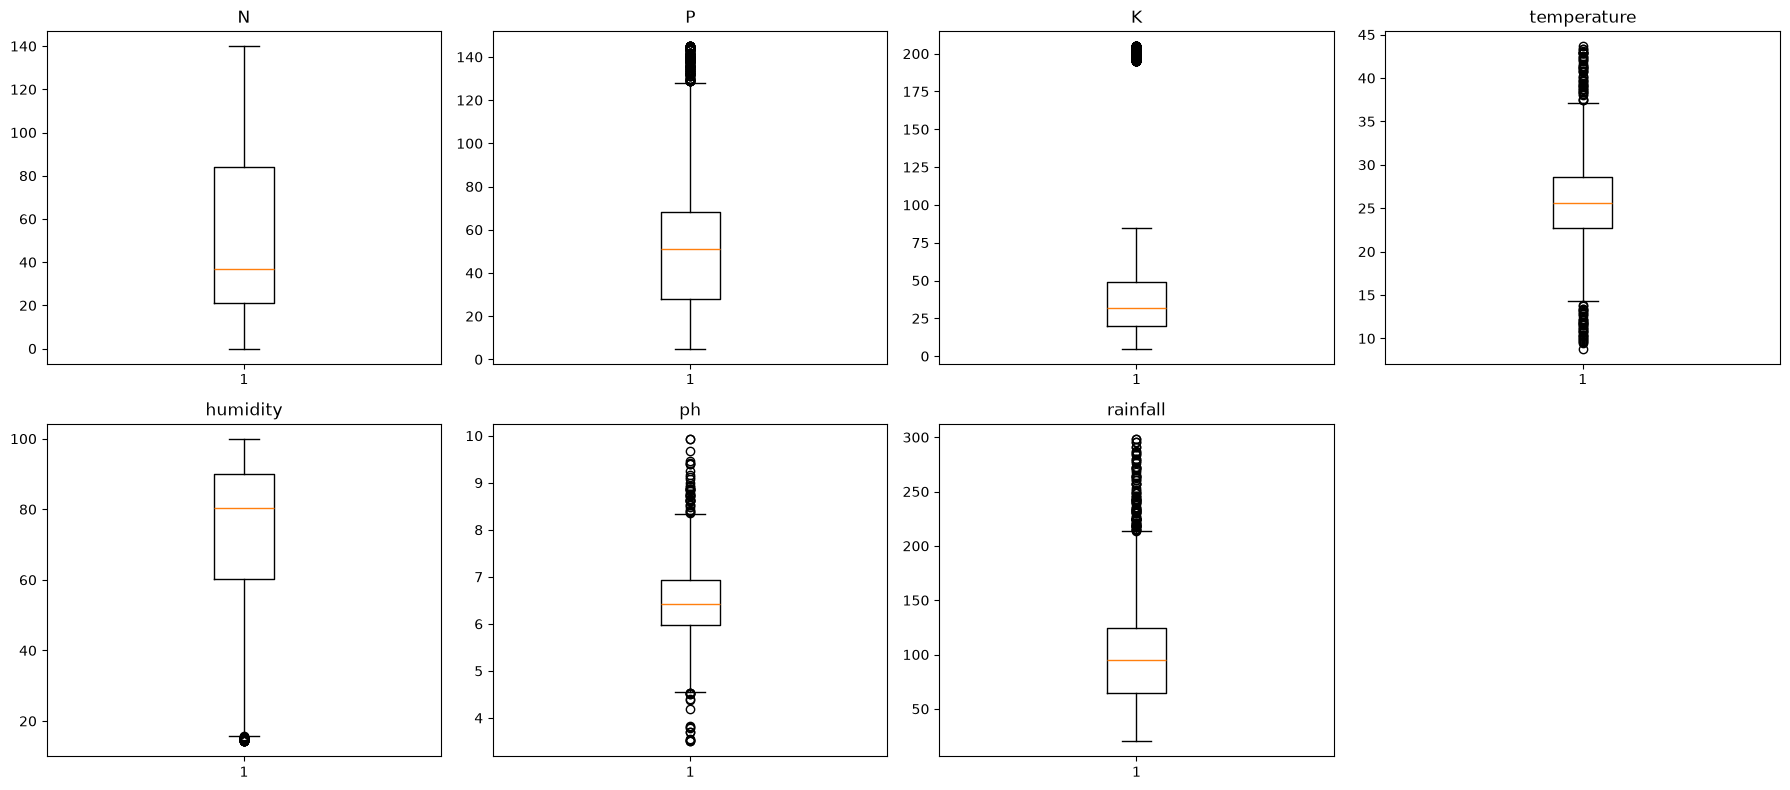

In [55]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

for i, col in enumerate(features):
    axes[i].boxplot(df[col])
    axes[i].set_title(col)

axes[7].set_visible(False)
plt.tight_layout()
plt.savefig('../figures/boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

boxes tells the outliers of dots

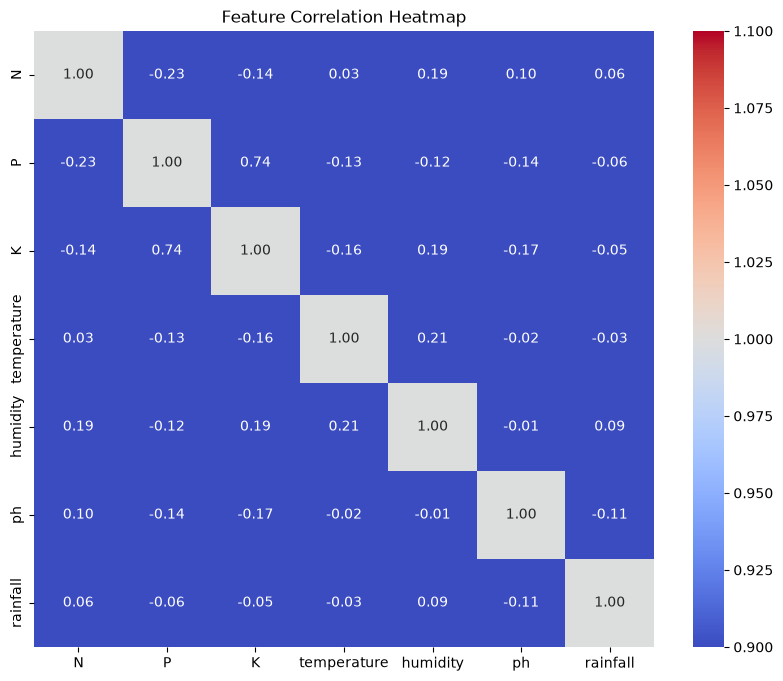

In [56]:
plt.figure(figsize=(10, 8))
corr = df[['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=1, vmax=1)
plt.title('Feature Correlation Heatmap')
plt.savefig('../figures/correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

blue = negative, red = positive, white = near zero

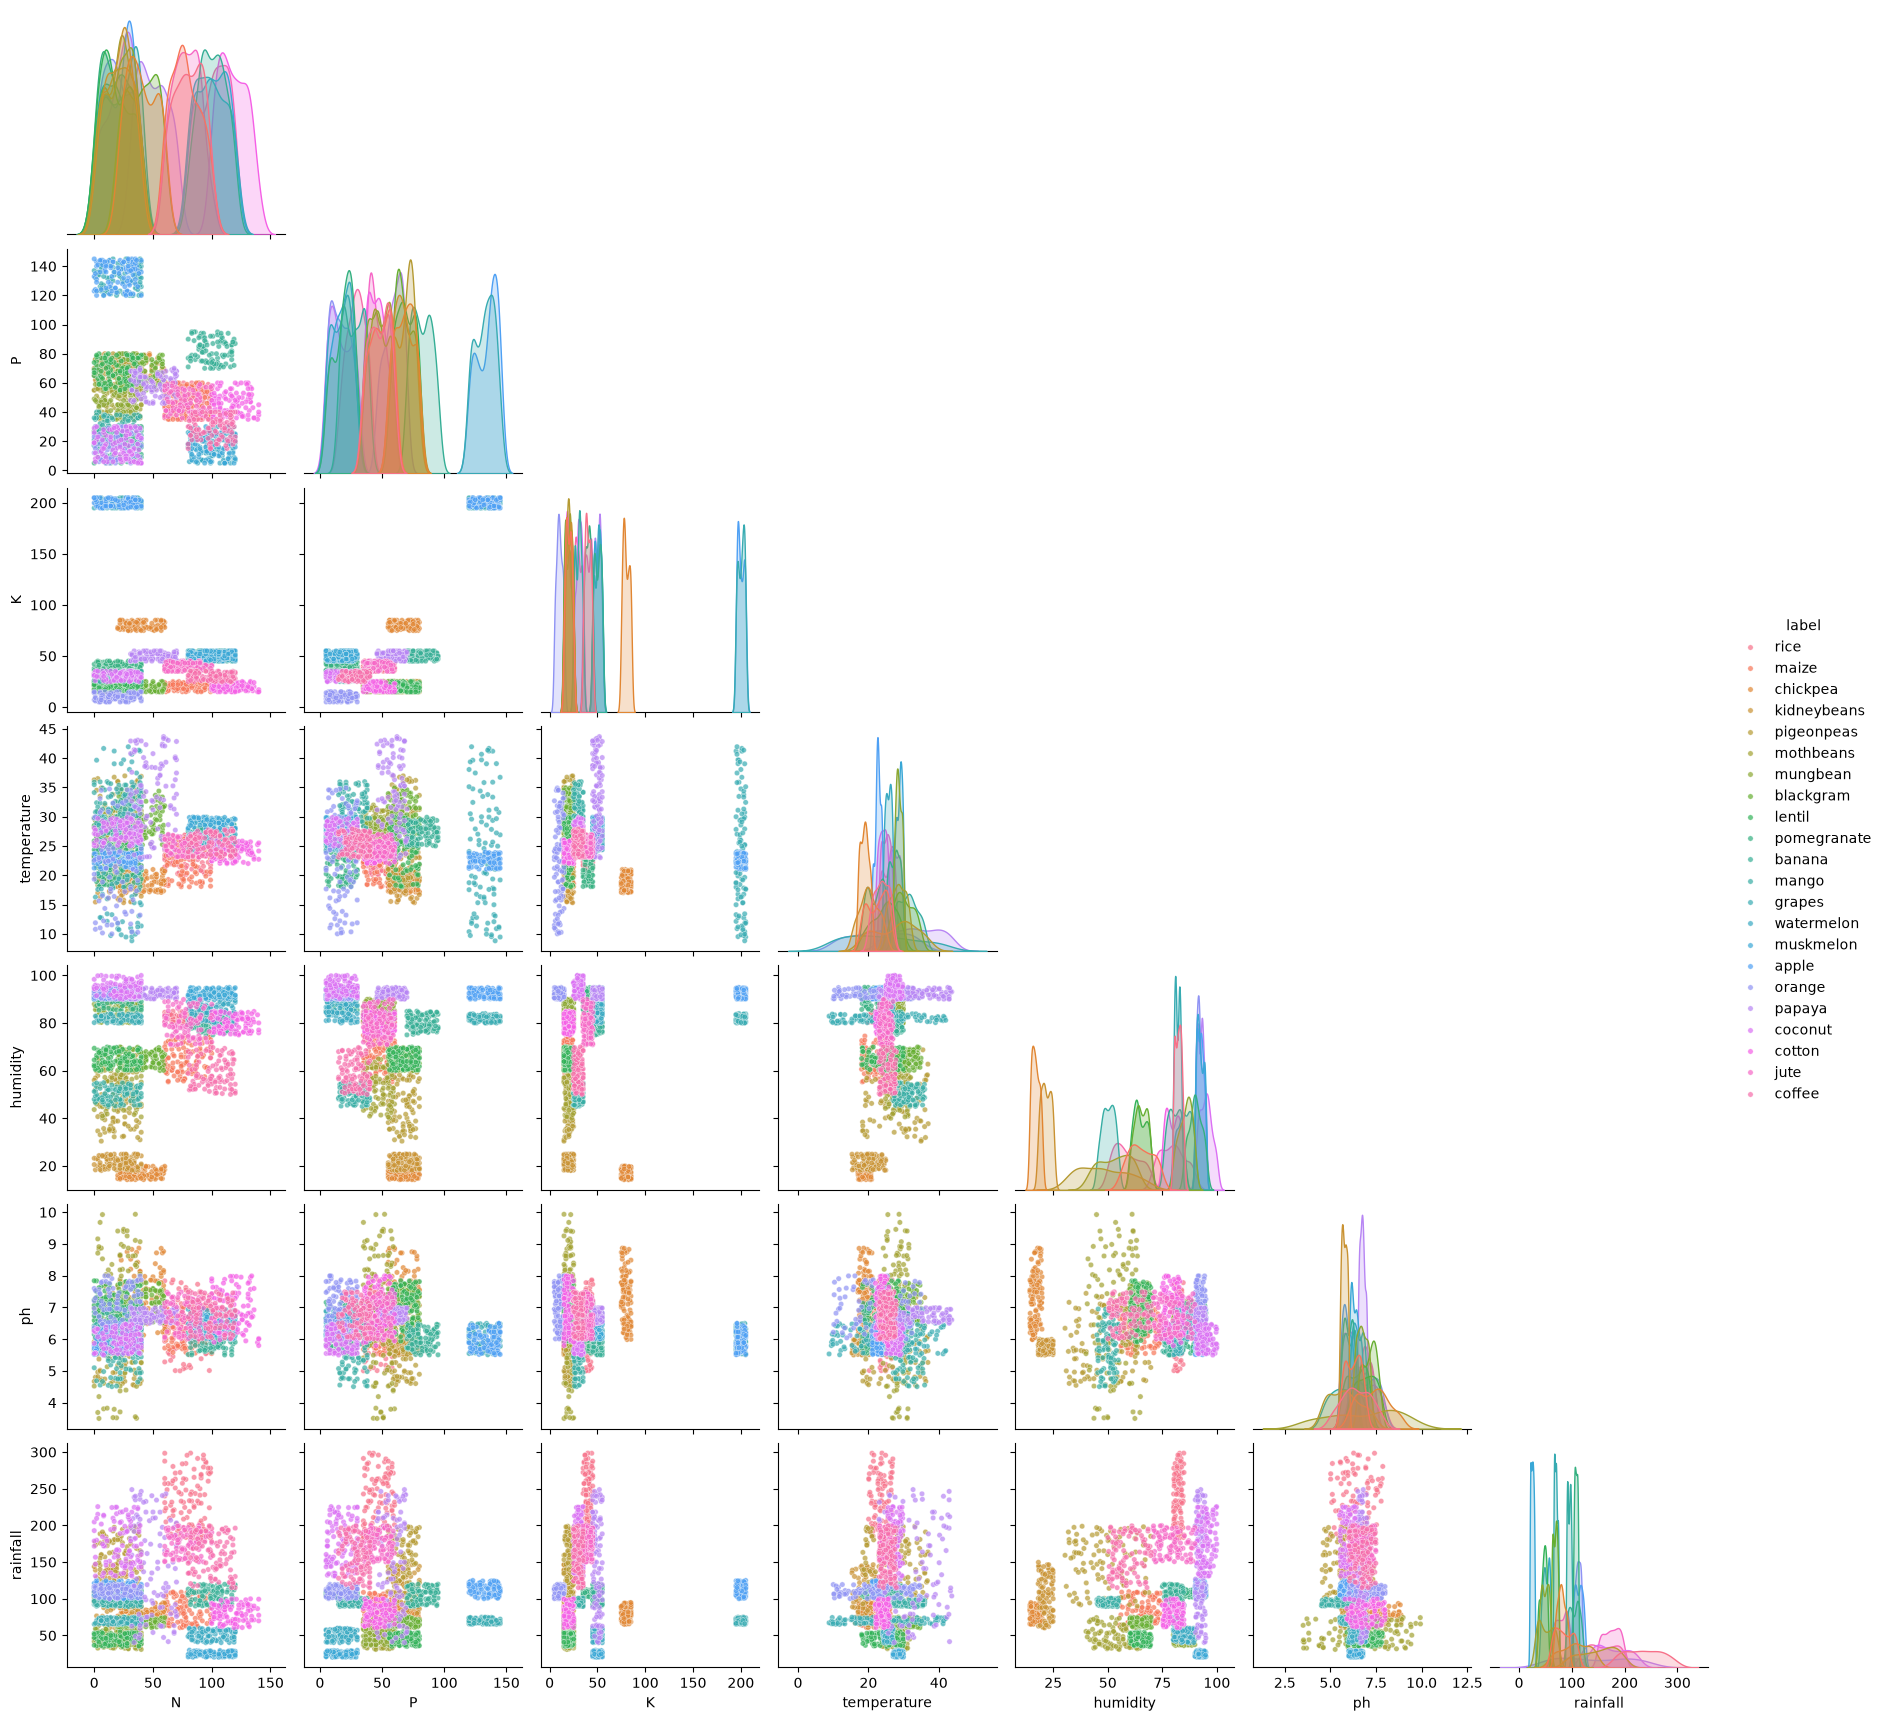

In [20]:
sns.pairplot(df, hue='label', corner=True, plot_kws={'s': 15, 'alpha': 0.7})
plt.show()

Visually this graph is wrong


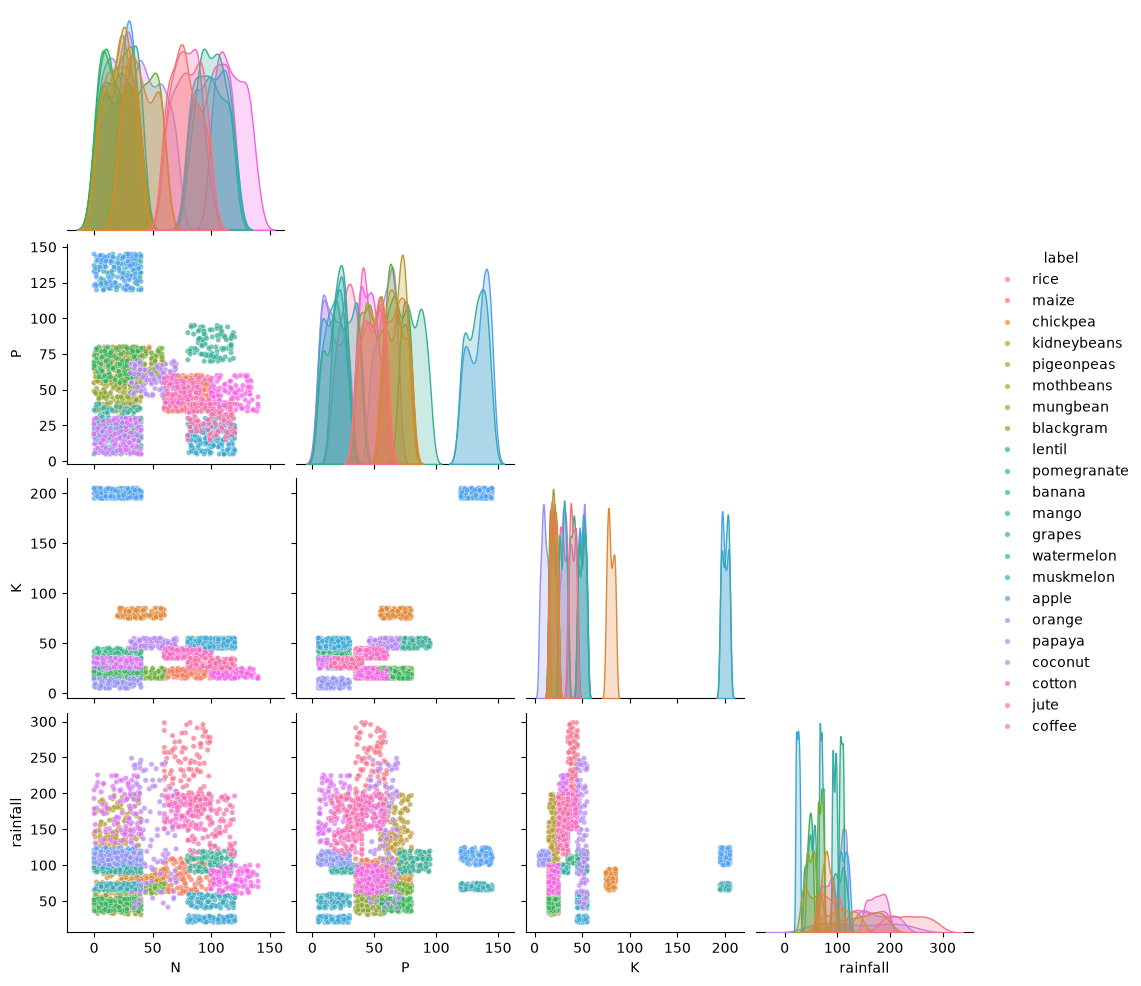

In [21]:
sns.pairplot(df[['N','P','K','rainfall','label']], hue='label', corner=True, plot_kws={'s':15,'alpha':0.7})
plt.show()

Same visually is not fully informative

### Preprocessing Phase

X = feature matrix (the inputs the model learns from)

y = target vector (what the model predicts)

In [22]:
X = df.drop('label', axis=1)
y = df['label']

print("X shape: ", X.shape)
print("y shape: ", y.shape)
print("\nX columns: ", list(X.columns))
print("\ny dtype: ", y.dtype)

X shape:  (2200, 7)
y shape:  (2200,)

X columns:  ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

y dtype:  str


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

# verify stratification worked
print("\nClass counts in y_train (first 3 crops):")
print(y_train.value_counts().head(3))
print("\nClass counts in y_test (first 3 crops):")
print(y_test.value_counts().head(3))

X_train: (1760, 7)
X_test:  (440, 7)
y_train: (1760,)
y_test:  (440,)

Class counts in y_train (first 3 crops):
label
orange         80
grapes         80
kidneybeans    80
Name: count, dtype: int64

Class counts in y_test (first 3 crops):
label
orange    20
banana    20
cotton    20
Name: count, dtype: int64


In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# fit ONLY on training data
scaler.fit(X_train)
# transform both using the training statistics
X_train_scaled = scaler.transform(X_train) #scaler.transform returns a NumPy array
X_test_scaled  = scaler.transform(X_test) #scaler.transform returns a NumPy array

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape: ", X_test_scaled.shape)

# verify scaling: training mean should be ~0, std ~1
print("\nTrain mean (should be ~0):", np.round(X_train_scaled.mean(axis=0), 4))
print("Train std  (should be ~1):", np.round(X_train_scaled.std(axis=0), 4))

# verify test set uses train stats (mean may not be exactly 0, but should be close)
print("\nTest mean (close to 0 but not exact):", np.round(X_test_scaled.mean(axis=0), 4))

X_train_scaled shape: (1760, 7)
X_test_scaled shape:  (440, 7)

Train mean (should be ~0): [ 0.  0.  0. -0. -0. -0.  0.]
Train std  (should be ~1): [1. 1. 1. 1. 1. 1. 1.]

Test mean (close to 0 but not exact): [ 0.0006  0.0035  0.0006  0.0067  0.0146 -0.0278  0.0011]


In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. instantiate
log_reg = LogisticRegression(max_iter=1000, random_state=42)

# 2. train
log_reg.fit(X_train_scaled, y_train)

# 3. predict
y_pred_log = log_reg.predict(X_test_scaled)

# 4. quick accuracy
acc_log = accuracy_score(y_test, y_pred_log)
print(f"Logistic Regression accuracy: {acc_log:.4f}")

Logistic Regression accuracy: 0.9727


In [26]:
results = {}
results['LogisticRegression'] = acc_log
print(results)

{'LogisticRegression': 0.9727272727272728}


In [27]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

acc_knn = accuracy_score(y_test, y_pred_knn)
print(f"KNN accuracy: {acc_knn:.4f}")

results['KNN'] = acc_knn
print(results)

KNN accuracy: 0.9795
{'LogisticRegression': 0.9727272727272728, 'KNN': 0.9795454545454545}


In [28]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42) # no max_depth → unlimited
dt.fit(X_train_scaled, y_train)

# training accuracy — remember to compare this to test
y_train_pred_dt = dt.predict(X_train_scaled)
y_test_pred_dt = dt.predict(X_test_scaled)

train_acc_dt = accuracy_score(y_train, y_train_pred_dt)
test_acc_dt = accuracy_score(y_test, y_test_pred_dt)

print(f"Decision Tree — Train accuracy: {train_acc_dt:.4f}")
print(f"Decision Tree — Test  accuracy: {test_acc_dt:.4f}")
print(f"Gap (train - test): {(train_acc_dt - test_acc_dt):.4f}")

results['Decision Tree'] = test_acc_dt
print(results)

Decision Tree — Train accuracy: 1.0000
Decision Tree — Test  accuracy: 0.9795
Gap (train - test): 0.0205
{'LogisticRegression': 0.9727272727272728, 'KNN': 0.9795454545454545, 'Decision Tree': 0.9795454545454545}


In [29]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)

y_train_pred_rf = rf.predict(X_train_scaled)
y_test_pred_rf = rf.predict(X_test_scaled)

train_acc_rf = accuracy_score(y_train, y_train_pred_rf)
test_acc_rf = accuracy_score(y_test, y_test_pred_rf)

print(f"Random Forest — Train accuracy: {train_acc_rf:.4f}")
print(f"Random Forest — Test  accuracy: {test_acc_rf:.4f}")
print(f"Gap: {(train_acc_rf - test_acc_rf):.4f}")

results['Random Forest'] = test_acc_rf
print(results)

Random Forest — Train accuracy: 1.0000
Random Forest — Test  accuracy: 0.9955
Gap: 0.0045
{'LogisticRegression': 0.9727272727272728, 'KNN': 0.9795454545454545, 'Decision Tree': 0.9795454545454545, 'Random Forest': 0.9954545454545455}


In [30]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf', random_state=42)
svm.fit(X_train_scaled, y_train)

y_train_pred_svm = svm.predict(X_train_scaled)
y_test_pred_svm = svm.predict(X_test_scaled)

train_acc_svm = accuracy_score(y_train, y_train_pred_svm)
test_acc_svm = accuracy_score(y_test, y_test_pred_svm)

print(f"SVM — Train accuracy: {train_acc_svm:.4f}")
print(f"SVM — Test  accuracy: {test_acc_svm:.4f}")
print(f"Gap: {(train_acc_svm - test_acc_svm):.4f}")

results['SVM'] = test_acc_svm
print(results)

SVM — Train accuracy: 0.9858
SVM — Test  accuracy: 0.9841
Gap: 0.0017
{'LogisticRegression': 0.9727272727272728, 'KNN': 0.9795454545454545, 'Decision Tree': 0.9795454545454545, 'Random Forest': 0.9954545454545455, 'SVM': 0.9840909090909091}


In [31]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train_scaled, y_train)

y_train_pred_nb = nb.predict(X_train_scaled)
y_test_pred_nb = nb.predict(X_test_scaled)

train_acc_nb = accuracy_score(y_train, y_train_pred_nb)
test_acc_nb = accuracy_score(y_test, y_test_pred_nb)

print(f"Naive Bayes — Train accuracy: {train_acc_nb:.4f}")
print(f"Naive Bayes — Test  accuracy: {test_acc_nb:.4f}")
print(f"Gap: {(train_acc_nb - test_acc_nb):.4f}")

results['Naive Bayes'] = test_acc_nb
print(results)

Naive Bayes — Train accuracy: 0.9949
Naive Bayes — Test  accuracy: 0.9955
Gap: -0.0006
{'LogisticRegression': 0.9727272727272728, 'KNN': 0.9795454545454545, 'Decision Tree': 0.9795454545454545, 'Random Forest': 0.9954545454545455, 'SVM': 0.9840909090909091, 'Naive Bayes': 0.9954545454545455}


In [32]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)
gb.fit(X_train_scaled, y_train)

y_train_pred_gb = gb.predict(X_train_scaled)
y_test_pred_gb = gb.predict(X_test_scaled)

train_acc_gb = accuracy_score(y_train, y_train_pred_gb)
test_acc_gb = accuracy_score(y_test, y_test_pred_gb)

print(f"Gradient Boosting — Train accuracy: {train_acc_gb:.4f}")
print(f"Gradient Boosting — Test  accuracy: {test_acc_gb:.4f}")
print(f"Gap: {(train_acc_gb - test_acc_gb):.4f}")

results['Gradient Boosting'] = test_acc_gb
print(results)

Gradient Boosting — Train accuracy: 1.0000
Gradient Boosting — Test  accuracy: 0.9886
Gap: 0.0114
{'LogisticRegression': 0.9727272727272728, 'KNN': 0.9795454545454545, 'Decision Tree': 0.9795454545454545, 'Random Forest': 0.9954545454545455, 'SVM': 0.9840909090909091, 'Naive Bayes': 0.9954545454545455, 'Gradient Boosting': 0.9886363636363636}


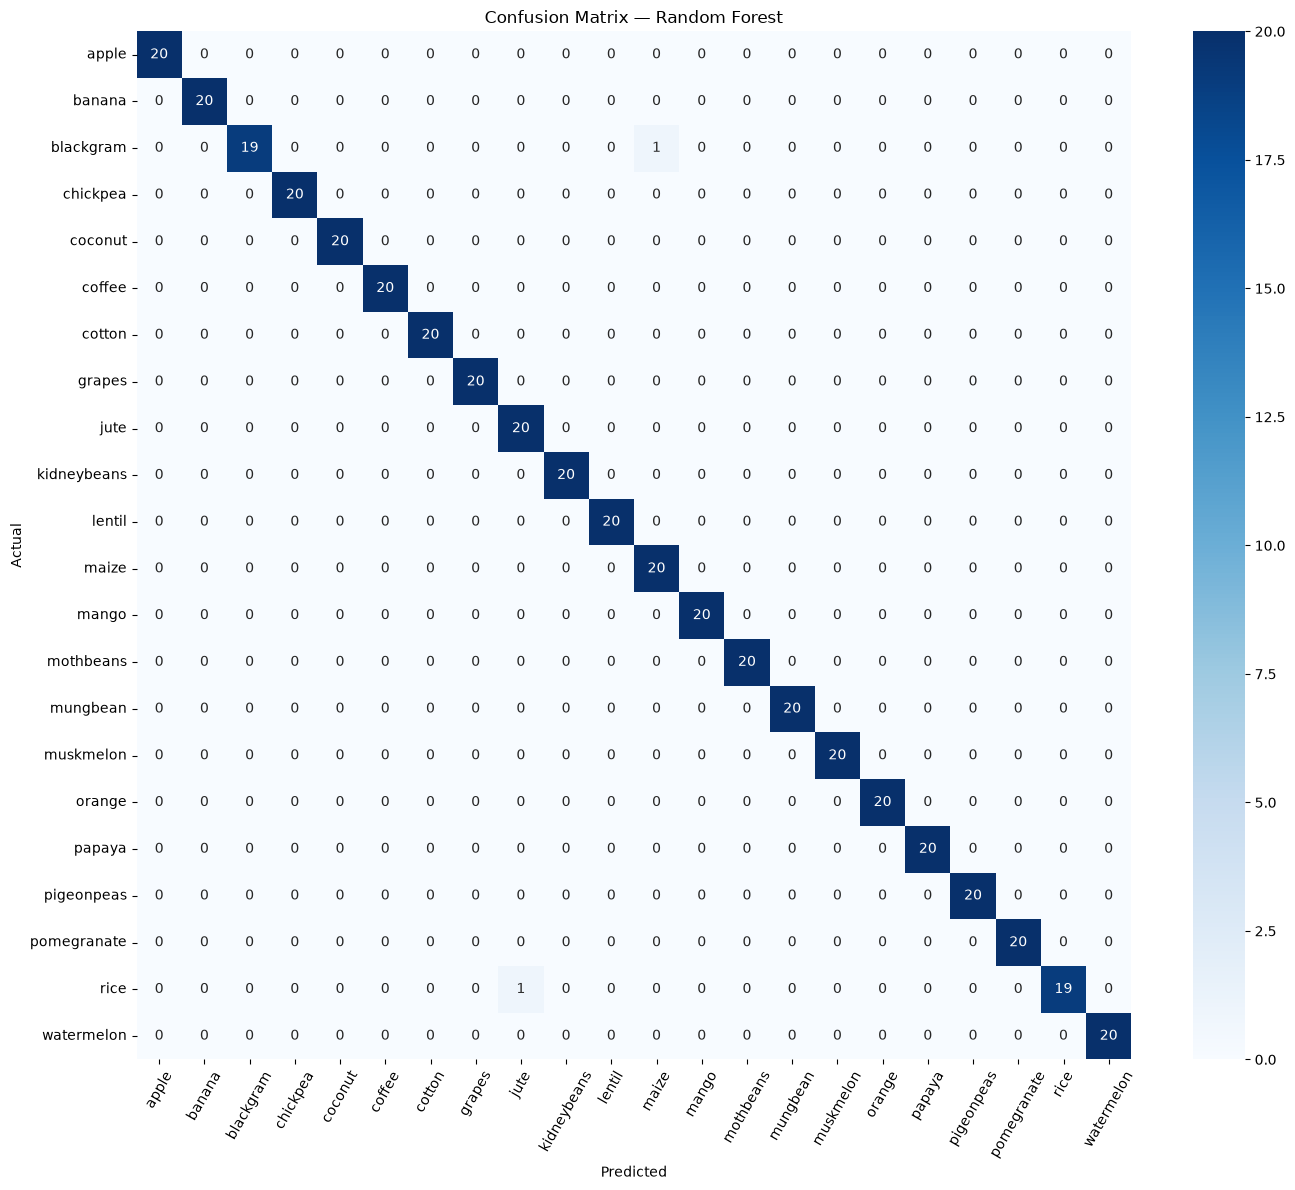

In [57]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_test_pred_rf)

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=rf.classes_,
    yticklabels=rf.classes_
)
plt.title('Confusion Matrix — Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=60)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('../figures/confusion_matrix_rf.png', dpi=150, bbox_inches='tight')
plt.show()

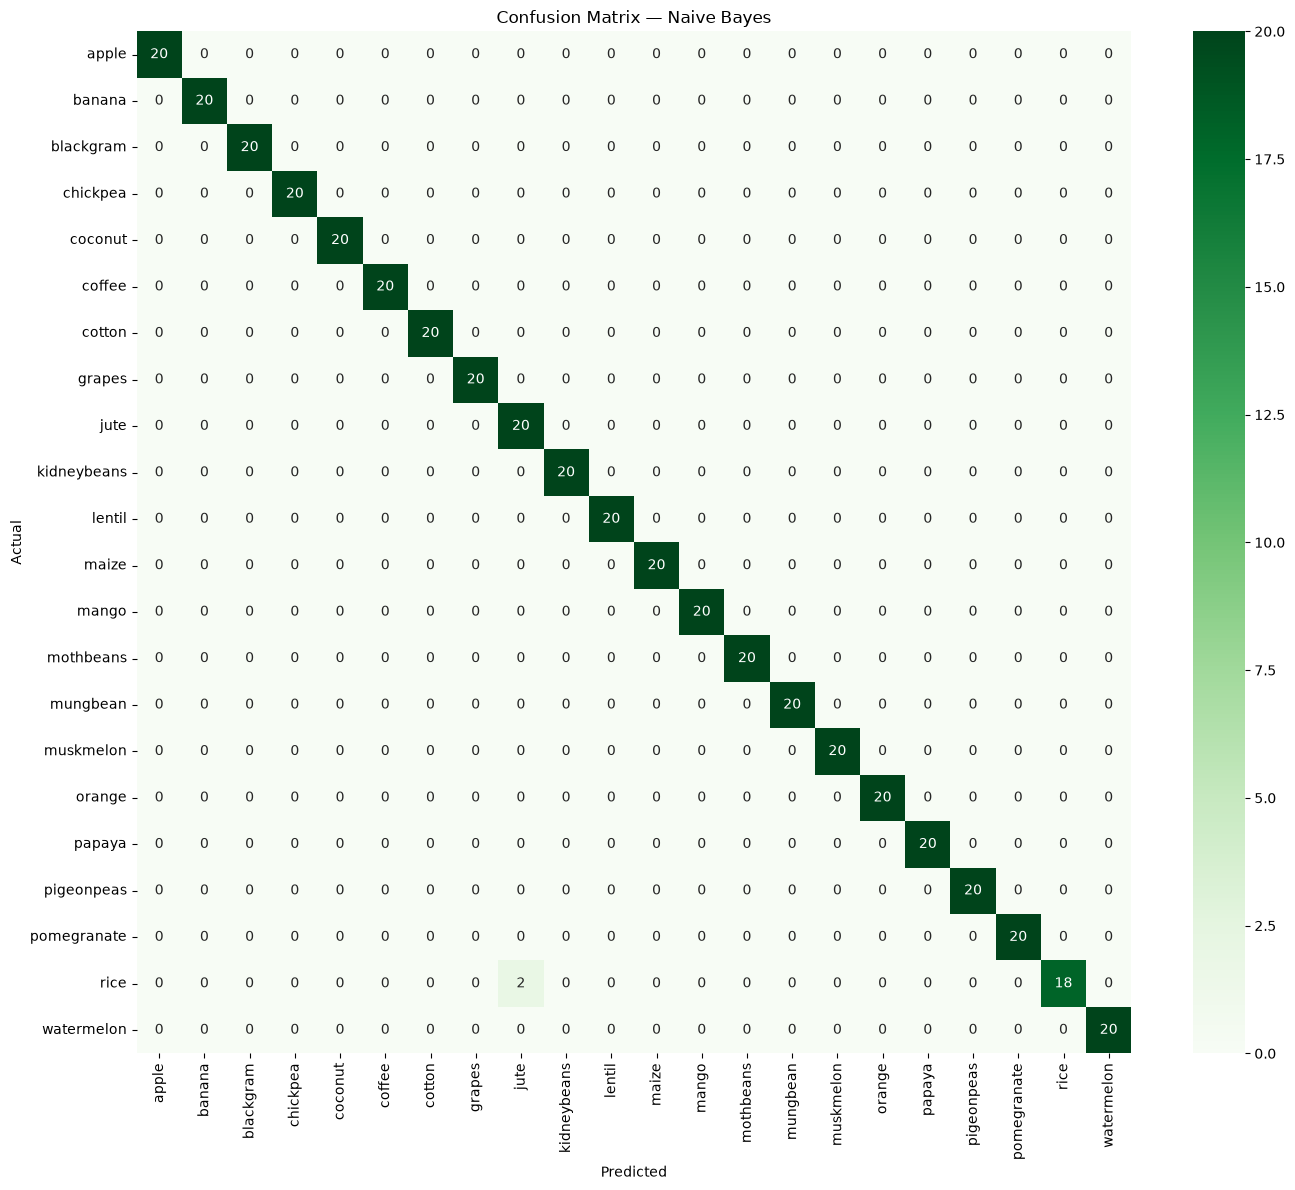

In [58]:
cm_nb = confusion_matrix(y_test, y_test_pred_nb)

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=nb.classes_,
    yticklabels=nb.classes_
)
plt.title('Confusion Matrix — Naive Bayes')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('../figures/confusion_matrix_nb.png', dpi=150, bbox_inches='tight')

plt.show()

In [35]:
from sklearn.metrics import classification_report

print("Classification Report -- Random Forest")
print(classification_report(y_test, y_test_pred_rf, digits=4))

Classification Report -- Random Forest
              precision    recall  f1-score   support

       apple     1.0000    1.0000    1.0000        20
      banana     1.0000    1.0000    1.0000        20
   blackgram     1.0000    0.9500    0.9744        20
    chickpea     1.0000    1.0000    1.0000        20
     coconut     1.0000    1.0000    1.0000        20
      coffee     1.0000    1.0000    1.0000        20
      cotton     1.0000    1.0000    1.0000        20
      grapes     1.0000    1.0000    1.0000        20
        jute     0.9524    1.0000    0.9756        20
 kidneybeans     1.0000    1.0000    1.0000        20
      lentil     1.0000    1.0000    1.0000        20
       maize     0.9524    1.0000    0.9756        20
       mango     1.0000    1.0000    1.0000        20
   mothbeans     1.0000    1.0000    1.0000        20
    mungbean     1.0000    1.0000    1.0000        20
   muskmelon     1.0000    1.0000    1.0000        20
      orange     1.0000    1.0000    1.000

In [36]:
from sklearn.model_selection import cross_val_score
# Cross-validate the top models on training data only
models = {
    'Logistic Regression': log_reg,
    'KNN': knn,
    'Decision Tree': dt,
    'Random Forest': rf,
    'SVM': svm,
    'Naive Bayes': nb,
    'Gradient Boosting': gb,
}

cv_results = {}

for name, model in models.items():
    scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='accuracy', n_jobs=-1)
    cv_results[name] = (scores.mean(), scores.std())
    print(f"{name:20s} -> mean: {scores.mean():.4f} std: {scores.std():.4f}")

Logistic Regression  -> mean: 0.9676 std: 0.0113
KNN                  -> mean: 0.9653 std: 0.0075
Decision Tree        -> mean: 0.9847 std: 0.0071
Random Forest        -> mean: 0.9932 std: 0.0043
SVM                  -> mean: 0.9761 std: 0.0075
Naive Bayes          -> mean: 0.9943 std: 0.0051
Gradient Boosting    -> mean: 0.9875 std: 0.0069


## Phase 5 — Hyperparameter Tuning


In [37]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, None],
    'min_samples_leaf': [1, 2, 4],
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_scaled, y_train)

print("Best params:", grid_search.best_params_)
print(f"Best CV score: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best params: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 300}
Best CV score: 0.9949


In [ ]:
from sklearn.metrics import accuracy_score

# the best estimator is refit on the full training set by GridSearchCV
best_rf = grid_search.best_estimator_

y_test_pred_best_rf = best_rf.predict(X_test_scaled)
test_acc_best_rf = accuracy_score(y_test, y_test_pred_best_rf)

print(f"Tuned RF — Test accuracy: {test_acc_best_rf:.4f}")
print(f"Default RF — Test accuracy: {results['Random Forest']:.4f}")
print(f"Difference: {(test_acc_best_rf - results['Random Forest']):.4f}")

Tuned RF — Test accuracy: 0.9932
Default RF — Test accuracy: 0.9955
Difference: -0.0023


In [40]:
results['Tuned Random Forest'] = test_acc_best_rf
print(results)


{'LogisticRegression': 0.9727272727272728, 'KNN': 0.9795454545454545, 'Decision Tree': 0.9795454545454545, 'Random Forest': 0.9954545454545455, 'SVM': 0.9840909090909091, 'Naive Bayes': 0.9954545454545455, 'Gradient Boosting': 0.9886363636363636, 'Tuned Random Forest': 0.9931818181818182}


In [41]:
from sklearn.ensemble import VotingClassifier
# rebuild models fresh so the ensemble uses identical training procedure
rf_v = RandomForestClassifier(n_estimators=100, random_state=42)
nb_v = GaussianNB()

ensemble = VotingClassifier(
    estimators=[('rf', rf_v), ('nb', nb_v)],
    voting='soft'
)

ensemble.fit(X_train_scaled, y_train)
y_pred_ens = ensemble.predict(X_test_scaled)

ens_acc = accuracy_score(y_test, y_pred_ens)
print(f"Ensemble (RF + NB) accuracy: {ens_acc:.4f}")
print(f"Random Forest:               {results['Random Forest']:.4f}")
print(f"Naive Bayes:                 {results['Naive Bayes']:.4f}")

results['Ensemble (RF + NB)'] = ens_acc
print("\n", results)

Ensemble (RF + NB) accuracy: 0.9955
Random Forest:               0.9955
Naive Bayes:                 0.9955

 {'LogisticRegression': 0.9727272727272728, 'KNN': 0.9795454545454545, 'Decision Tree': 0.9795454545454545, 'Random Forest': 0.9954545454545455, 'SVM': 0.9840909090909091, 'Naive Bayes': 0.9954545454545455, 'Gradient Boosting': 0.9886363636363636, 'Tuned Random Forest': 0.9931818181818182, 'Ensemble (RF + NB)': 0.9954545454545455}


In [42]:
cm_ens = confusion_matrix(y_test, y_pred_ens)
print(cm_ens)

[[20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0

In [43]:
import joblib
import os

# create the models directory if it doesn't exist
os.makedirs('models', exist_ok=True)

# retrain the final model to have a fresh, clean instance
final_model = RandomForestClassifier(n_estimators=100, random_state=42)
final_model.fit(X_train_scaled, y_train)

# save model and scaler
joblib.dump(final_model, 'models/crop_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')

# save metadata for future reference (feature names, class names, metrics)
metadata = {
    'features': list(X.columns),
    'classes': list(final_model.classes_),
    'test_accuracy': float(accuracy_score(y_test, final_model.predict(X_test_scaled))),
    'cv_mean': 0.9932,
    'cv_std': 0.0043,
    'n_estimators': 100,
    'random_state': 42,
}
import json
with open('models/metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

print("Saved:")
print("  models/crop_model.pkl")
print("  models/scaler.pkl")
print("  models/metadata.json")

Saved:
  models/crop_model.pkl
  models/scaler.pkl
  models/metadata.json


In [44]:
!ls -lh models/

total 3.5M
-rw-rw-r-- 1 faraz-ul-hassan faraz-ul-hassan 3.5M Nov 11 10:33 crop_model.pkl
-rw-rw-r-- 1 faraz-ul-hassan faraz-ul-hassan  587 Nov 11 10:33 metadata.json
-rw-rw-r-- 1 faraz-ul-hassan faraz-ul-hassan 1.1K Nov 11 10:33 scaler.pkl


In [45]:
!ls -lh ../models/

ls: cannot access '../models/': No such file or directory


In [46]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
MODEL_DIR = PROJECT_ROOT / 'models'

In [47]:
# load the saved artifacts
loaded_model  = joblib.load(MODEL_DIR / 'crop_model.pkl')
loaded_scaler = joblib.load(MODEL_DIR / 'scaler.pkl')

# a new "unknown" sample — order matters! must match X.columns
# N, P, K, temperature, humidity, ph, rainfall
new_sample = np.array([[90, 42, 43, 20.8, 82.0, 6.5, 202.9]])

# scale it with the loaded scaler (CRITICAL — same scaler as training)
new_sample_scaled = loaded_scaler.transform(new_sample)

# predict
prediction = loaded_model.predict(new_sample_scaled)
print("Predicted crop:", prediction[0])

# also show probabilities for transparency
probs = loaded_model.predict_proba(new_sample_scaled)[0]
top_idx = np.argsort(probs)[-3:][::-1]  # top 3
print("\nTop 3 predictions:")
for i in top_idx:
    print(f"  {loaded_model.classes_[i]:12s} → {probs[i]:.4f}")

Predicted crop: rice

Top 3 predictions:
  rice         → 0.9000
  jute         → 0.1000
  pomegranate  → 0.0000


/home/faraz-ul-hassan/Development/projects/machine-learning/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
new_sample = pd.DataFrame(
    [[90, 42, 43, 20.8, 82.0, 6.5, 202.9]],
    columns=['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
)

new_sample_scaled = loaded_scaler.transform(new_sample)
prediction = loaded_model.predict(new_sample_scaled)
print("Predicted crop:", prediction[0])
# to remove warning we done it

Predicted crop: rice


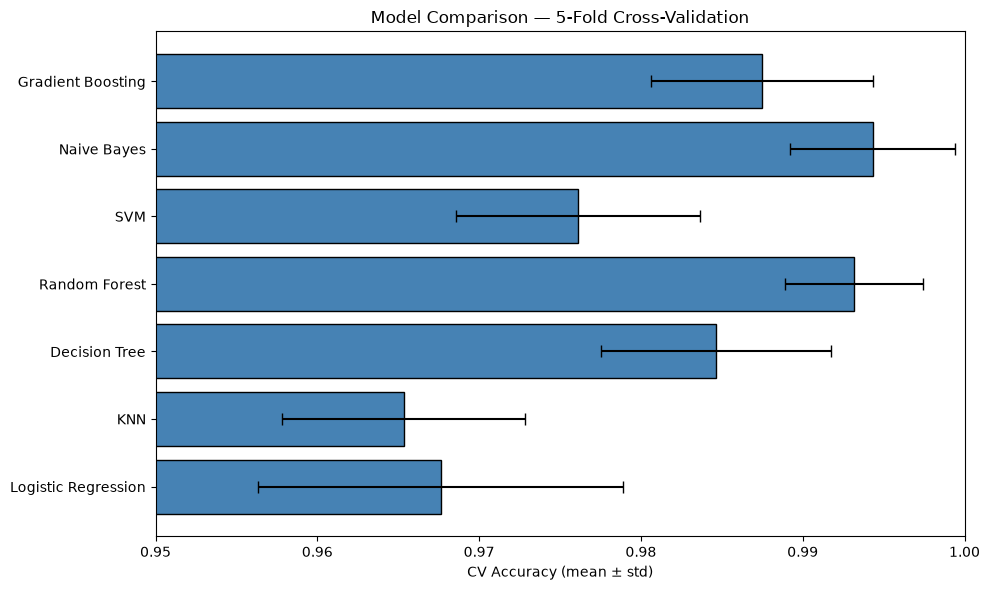

In [59]:
import numpy as np

names = list(cv_results.keys())
means = [cv_results[n][0] for n in names]
stds  = [cv_results[n][1] for n in names]

plt.figure(figsize=(10, 6))
plt.barh(names, means, xerr=stds, color='steelblue', edgecolor='black', capsize=4)
plt.xlim(0.95, 1.0)
plt.xlabel('CV Accuracy (mean ± std)')
plt.title('Model Comparison — 5-Fold Cross-Validation')
plt.tight_layout()
plt.savefig('../figures/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()